# My Tu Verras — complete answer

The project asks for eight functions and a prediction model, on the Boston housing dataset Qwasar
provides. This notebook is the finished submission: every required function, the answers to the
questions the subject poses in the text, and the experiment campaign that decides what the final
model should be.

```
load_dataset()                      print_histograms(dataset)
print_summarize_dataset(dataset)    compute_correlations_matrix(dataset)
clean_dataset(dataset)              print_scatter_matrix(dataset)
boston_fit_model(dataset)           boston_predict(estimator, array_to_predict)
```

In [ ]:
# ABOUTME: Complete solution to the Qwasar "My Tu Verras" project (Boston housing prices).
# ABOUTME: Analysis functions, prediction model, and the measured comparison behind the model choice.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

def _data_path(name="boston.csv"):
    for up in range(4):
        p = Path(*([".."] * up), "data", name)
        if p.exists():
            return p
    raise FileNotFoundError("run `uv run get_data.py` in workshops/ first")

## 1. Loading and summarising

Note the target column: the subject's text calls it `MEDV`, the file calls it **`MDEV`**. We take
the name from the file.

In [ ]:
def load_dataset():
    """The Boston housing dataset exactly as Qwasar publishes it."""
    return pd.read_csv(_data_path("boston.csv"))

boston_dataframe = load_dataset()
TARGET = "MDEV"          # as spelled in the file, not as spelled in the subject text


def print_summarize_dataset(dataset):
    """Dimension, first rows, statistical summary."""
    print("Dataset dimension:")
    print(dataset.shape)
    print("\nFirst 10 rows of dataset:")
    print(dataset.head(10))
    print("\nStatistical summary:")
    print(dataset.describe())

print_summarize_dataset(boston_dataframe)

Dataset dimension:
(506, 14)

First 10 rows of dataset:
      CRIM    ZN  INDUS  CHAS    NOX     RM    AGE     DIS  RAD    TAX  PTRATIO       B  LSTAT  MDEV
0  0.00632  18.0   2.31   0.0  0.538  6.575   65.2  4.0900  1.0  296.0     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07   0.0  0.469  6.421   78.9  4.9671  2.0  242.0     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07   0.0  0.469  7.185   61.1  4.9671  2.0  242.0     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18   0.0  0.458  6.998   45.8  6.0622  3.0  222.0     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18   0.0  0.458  7.147   54.2  6.0622  3.0  222.0     18.7  396.90   5.33  36.2
5  0.02985   0.0   2.18   0.0  0.458  6.430   58.7  6.0622  3.0  222.0     18.7  394.12   5.21  28.7
6  0.08829  12.5   7.87   0.0  0.524  6.012   66.6  5.5605  5.0  311.0     15.2  395.60  12.43  22.9
7  0.14455  12.5   7.87   0.0  0.524  6.172   96.1  5.9505  5.0  311.0     15.2  396.90  19.15  27.1
8  0.21124  12.5   7.87   0.0  0.52

In [ ]:
def clean_dataset(boston_dataframe):
    """Drop any row carrying a missing value, as the subject asks."""
    return boston_dataframe.dropna()

before = len(boston_dataframe)
boston_dataframe = clean_dataset(boston_dataframe)
print(f"rows: {before} -> {len(boston_dataframe)}")
print("missing values:", int(boston_dataframe.isna().sum().sum()))
print("duplicate rows:", int(boston_dataframe.duplicated().sum()))

rows: 506 -> 506
missing values: 0
duplicate rows: 0


**Zero rows dropped: the file has no missing values and no duplicates.** That is a result worth
stating, not a non-event — and it is not the same as the data being correct. Three things are
wrong with it despite being complete:

| finding | evidence |
|---|---|
| the target is **censored** at 50 | 16 towns sit at exactly 50.0, the maximum, and it is the single most frequent value |
| `CHAS` is nearly constant | 93 % of towns are 0 |
| a block of 132 identical towns | `RAD = 24` and `TAX = 666` co-occur exactly 132 times |

In [ ]:
print("towns at exactly 50.0:", int((boston_dataframe[TARGET] == 50).sum()),
      "| maximum:", boston_dataframe[TARGET].max())
print("most frequent target values:", boston_dataframe[TARGET].value_counts().head(3).to_dict())
print("CHAS == 0:", f"{(boston_dataframe.CHAS == 0).mean():.1%}")
print("RAD==24 & TAX==666:", int(((boston_dataframe.RAD == 24) & (boston_dataframe.TAX == 666)).sum()))

towns at exactly 50.0: 16 | maximum: 50.0
most frequent target values: {50.0: 16, 25.0: 8, 23.1: 7}
CHAS == 0: 93.1%
RAD==24 & TAX==666: 132


## 2. Histograms and correlations

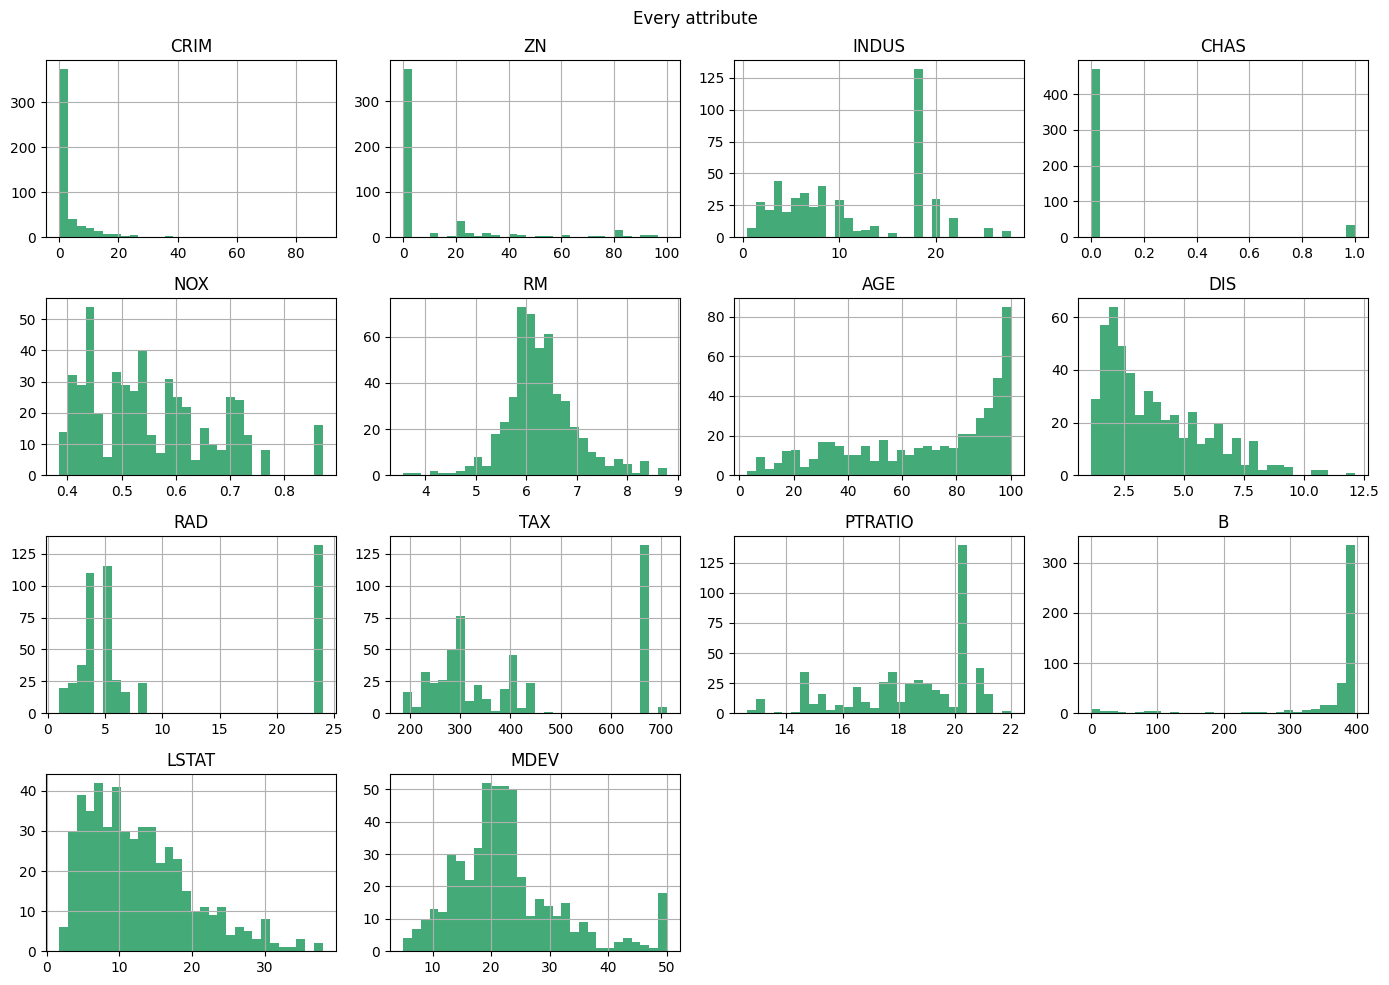

In [ ]:
def print_histograms(boston_dataframe):
    """One histogram per attribute."""
    boston_dataframe.hist(bins=30, figsize=(14, 10), color="#4a7")
    plt.suptitle("Every attribute")
    plt.tight_layout()

print_histograms(boston_dataframe)

In [ ]:
def compute_correlations_matrix(boston_dataframe):
    """Pearson correlation between every pair of attributes."""
    return boston_dataframe.corr()

correlations = compute_correlations_matrix(boston_dataframe)
print("correlations with", TARGET)
print(correlations[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

correlations with MDEV
LSTAT     -0.738
RM         0.695
PTRATIO   -0.508
INDUS     -0.484
TAX       -0.469
NOX       -0.427
CRIM      -0.386
RAD       -0.382
AGE       -0.377
ZN         0.360
B          0.333
DIS        0.250
CHAS       0.175


The subject asks two questions directly, and here are the answers:

- **Correlation between the median value and the number of rooms:** `RM` = **+0.695**, the
  strongest positive. More rooms, higher price — as expected.
- **Most negatively correlated attribute:** `LSTAT` = **−0.738**, the percentage of lower-status
  population. It is stronger than `RM` in absolute terms, so the best single predictor of a town's
  house price is not its houses, it is its people.

A third observation the subject does not ask for: `B` is defined as `1000(Bk − 0.63)²` where Bk is
the proportion of Black residents. scikit-learn removed this dataset in version 1.2 over exactly
that. It is measured below and it does not earn its place.

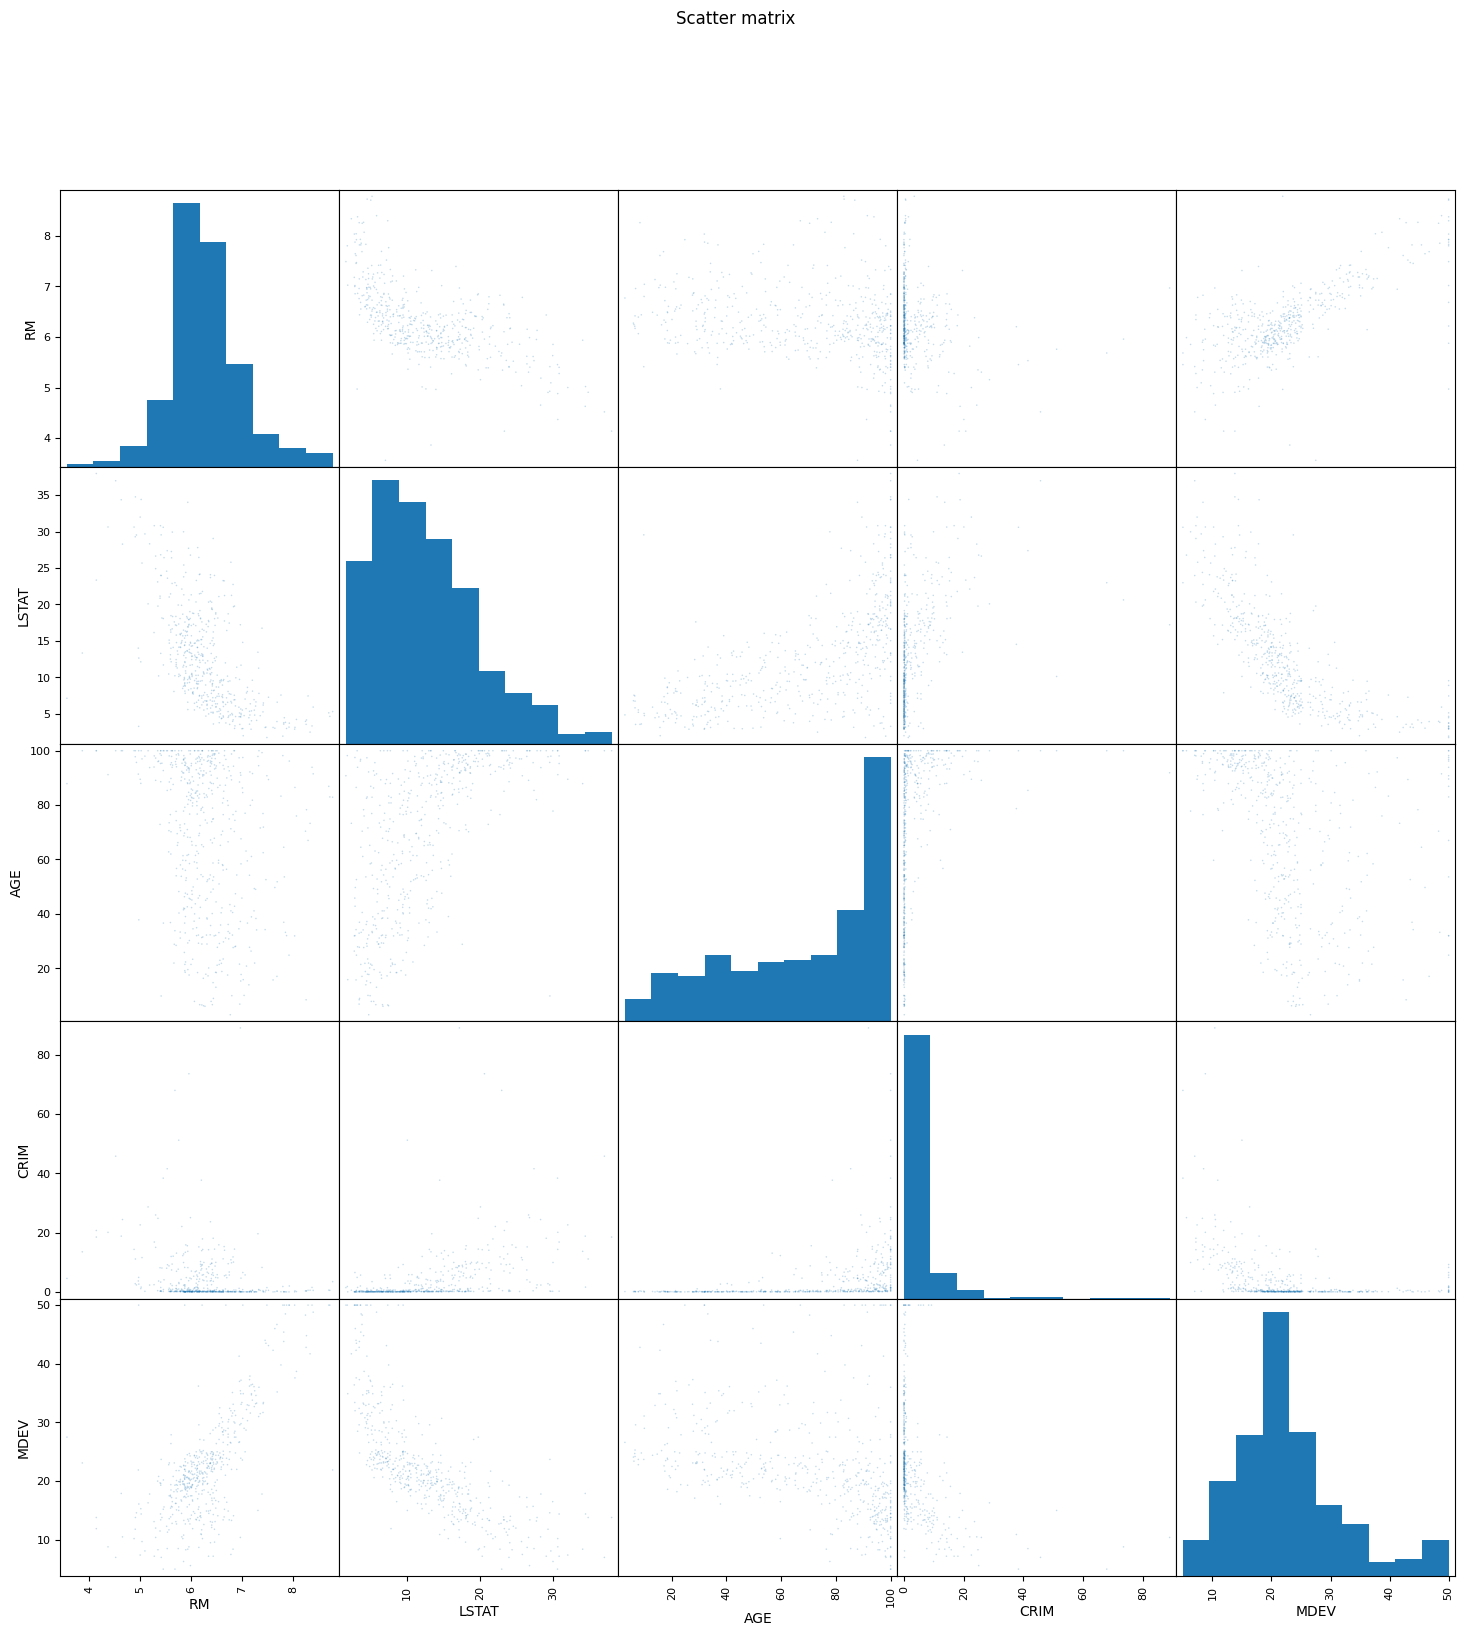

In [ ]:
def print_scatter_matrix(boston_dataframe):
    """Every attribute against every other; histograms on the diagonal."""
    pd.plotting.scatter_matrix(boston_dataframe, figsize=(18, 18), diagonal="hist", alpha=0.25, s=5)
    plt.suptitle("Scatter matrix")

print_scatter_matrix(boston_dataframe[["RM", "LSTAT", "AGE", "CRIM", TARGET]])

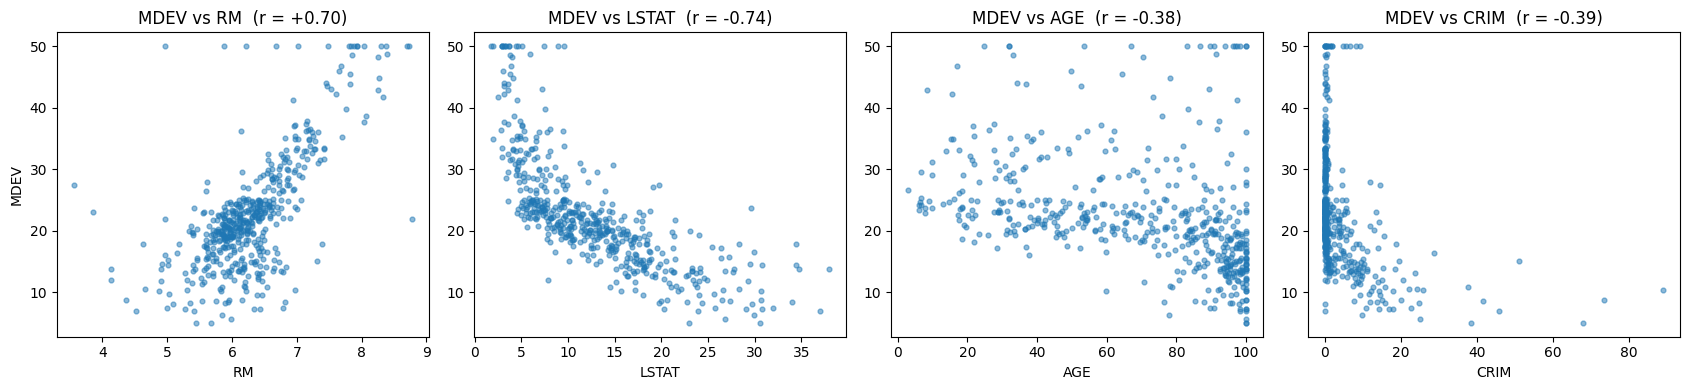

In [ ]:
# The subject asks for MDEV against RM, then against LSTAT, AGE and CRIM.
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, ["RM", "LSTAT", "AGE", "CRIM"]):
    ax.scatter(boston_dataframe[col], boston_dataframe[TARGET], s=12, alpha=0.5)
    ax.set_xlabel(col); ax.set_title(f"{TARGET} vs {col}  (r = {correlations.loc[col, TARGET]:+.2f})")
axes[0].set_ylabel(TARGET)
plt.tight_layout()

Two things to read off these, both of which matter for the model:

- **A flat line of points along the top of every panel** — the 16 censored towns, stuck at 50
  whatever their rooms, status, age or crime.
- **`LSTAT` is curved, not straight.** The relationship bends: price falls steeply at low LSTAT and
  flattens out. A straight line cannot follow that, which is the single biggest limitation of the
  linear model below — and the cheapest thing to fix.

## 3. The prediction model

Train / validation / test, 70 / 15 / 15, so that model choices are made on validation and the test
set is spent once.

In [ ]:
FEATURES = [c for c in boston_dataframe.columns if c != TARGET]

def split(df, seed=SEED):
    shuffled = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    a, b = int(0.70 * len(df)), int(0.85 * len(df))
    return shuffled[:a], shuffled[a:b], shuffled[b:]

train, val, test = split(boston_dataframe)

def boston_fit_model(dataset):
    """Fit the prediction model on a dataset holding the features and the target."""
    return LinearRegression().fit(dataset[FEATURES], dataset[TARGET])

def boston_predict(estimator, array_to_predict):
    """Predict median values for new towns."""
    return estimator.predict(array_to_predict)

def print_model_prediction_evaluator(base_test, prediction):
    print("Mean Absolute Error:", mean_absolute_error(base_test, prediction))
    print("Mean Squared Error:", mean_squared_error(base_test, prediction))
    print("Root Mean Squared Error:", np.sqrt(mean_squared_error(base_test, prediction)))

estimator = boston_fit_model(train)
prediction = boston_predict(estimator, val[FEATURES])
print_model_prediction_evaluator(val[TARGET], prediction)

dumb = np.full(len(val), train[TARGET].mean())
print(f"\npredict-the-mean RMSE: {np.sqrt(mean_squared_error(val[TARGET], dumb)):.3f}  <- the bar to beat")

Mean Absolute Error: 3.62207956208715
Mean Squared Error: 22.238273042099923
Root Mean Squared Error: 4.71574734714445

predict-the-mean RMSE: 9.712  <- the bar to beat


**RMSE 4.72 against a predict-the-mean bar of 9.71.** The model halves the error of knowing
nothing. That pair of numbers is the only honest way to report a score.

## 4. What actually improves it

Rather than guess, every candidate change is run on **30 different splits** and compared **paired**
against the baseline on the same splits. This matters more than it sounds: the baseline moves by
±0.68 RMSE depending on which towns land in validation, which is larger than most of the effects
being tested. A single split cannot resolve them.

In [ ]:
def run(tr, va, log=False, drop_b=False, lstat_log=False, rf=False, drop_cens=False, rooms2=False):
    """One configuration, one validation RMSE, always scored in the original dollars."""
    tr, va = tr.copy(), va.copy()
    feats = [f for f in FEATURES if not (drop_b and f == "B")]
    for d in (tr, va):
        if lstat_log:
            d["LSTAT_log"] = np.log(d.LSTAT)
        if rooms2:
            d["RM2"] = d.RM ** 2
    if lstat_log:
        feats = [f for f in feats if f != "LSTAT"] + ["LSTAT_log"]
    if rooms2:
        feats = feats + ["RM2"]
    if drop_cens:
        tr = tr[tr[TARGET] < 50]
    y = np.log(tr[TARGET]) if log else tr[TARGET]
    model = RandomForestRegressor(n_estimators=300, random_state=0) if rf else LinearRegression()
    model.fit(tr[feats], y)
    pred = model.predict(va[feats])
    if log:
        pred = np.exp(pred)
    return float(np.sqrt(mean_squared_error(va[TARGET], pred)))

CONFIGS = {
    "0 baseline (linear, all features)": {},
    "1 log(price)":                      dict(log=True),
    "2 log(LSTAT)":                      dict(lstat_log=True),
    "3 log(price) + log(LSTAT)":         dict(log=True, lstat_log=True),
    "4 (3) + RM squared":                dict(log=True, lstat_log=True, rooms2=True),
    "5 drop B":                          dict(drop_b=True),
    "6 drop censored from train":        dict(drop_cens=True),
    "7 RandomForest":                    dict(rf=True),
}
raw = pd.DataFrame([{name: run(*split(boston_dataframe, seed=s)[:2], **cfg)
                     for name, cfg in CONFIGS.items()} for s in range(30)])
base = raw["0 baseline (linear, all features)"]
campaign = pd.DataFrame({"mean_rmse": raw.mean().round(3),
                         "paired_delta": raw.sub(base, axis=0).mean().round(3),
                         "delta_std": raw.sub(base, axis=0).std().round(3),
                         "wins_of_30": (raw.sub(base, axis=0) < -1e-12).sum()})
print(campaign.sort_values("paired_delta").to_string())
print(f"\nbaseline moves by +/- {base.std():.3f} RMSE depending only on the split")

                                   mean_rmse  paired_delta  delta_std  wins_of_30
7 RandomForest                         3.358        -1.474      0.515          30
4 (3) + RM squared                     4.182        -0.650      0.458          27
3 log(price) + log(LSTAT)              4.276        -0.555      0.331          29
2 log(LSTAT)                           4.344        -0.488      0.270          30
1 log(price)                           4.463        -0.369      0.174          30
0 baseline (linear, all features)      4.832         0.000      0.000           0
5 drop B                               4.901         0.069      0.056           5
6 drop censored from train             5.004         0.173      0.268           8

baseline moves by +/- 0.675 RMSE depending only on the split


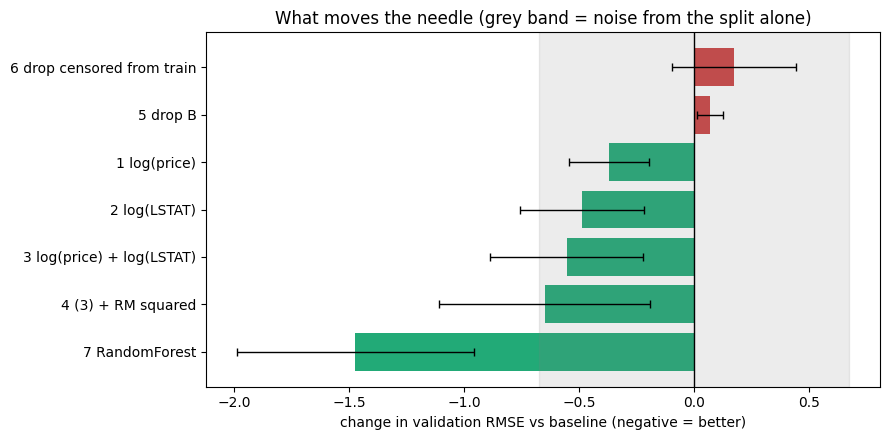

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordered = campaign.drop(index="0 baseline (linear, all features)").sort_values("paired_delta")
colors = ["#2a7" if d < 0 else "#c44" for d in ordered.paired_delta]
ax.barh(range(len(ordered)), ordered.paired_delta, color=colors)
ax.errorbar(ordered.paired_delta, range(len(ordered)), xerr=ordered.delta_std,
            fmt="none", ecolor="k", capsize=3, lw=1)
ax.axvline(0, color="k", lw=1)
ax.axvspan(-base.std(), base.std(), color="grey", alpha=0.15)
ax.set_yticks(range(len(ordered)), ordered.index)
ax.set_xlabel("change in validation RMSE vs baseline (negative = better)")
ax.set_title("What moves the needle (grey band = noise from the split alone)")
plt.tight_layout()

Read the chart with the grey band in mind: **anything inside it is smaller than the noise from
re-splitting the data**, so a single-split experiment could not tell it apart from luck.

| change | delta RMSE | wins | verdict |
|---|---|---|---|
| **RandomForest** | **−1.47** | 30/30 | the biggest single gain, by a distance |
| **(3) + RM²** | −0.65 | 27/30 | curvature in rooms helps a little more |
| **log(price) + log(LSTAT)** | −0.56 | 29/30 | the best *linear* model |
| **log(LSTAT)** | −0.49 | 30/30 | fixes the curve seen in the scatter plot |
| **log(price)** | −0.37 | 30/30 | fixes the right-skewed target |
| drop B | +0.07 | 5/30 | **costs nothing** — the race proxy is not needed |
| drop censored from train | +0.17 | 8/30 | hurts: removes the only expensive examples |

## 5. The final model and the test measurement

The decisions are made. The winner is retrained on train + validation and measured **once** on the
test set.

In [ ]:
winner = campaign.paired_delta.idxmin()
full_train = pd.concat([train, val], ignore_index=True)
test_rmse = run(full_train, test, **CONFIGS[winner])

print(f"winner                    : {winner}")
print(f"its validation RMSE       : {campaign.loc[winner, 'mean_rmse']:.3f}  (mean over 30 splits)")
print(f"its TEST RMSE             : {test_rmse:.3f}   <- measured once")
print(f"best linear model instead : {campaign.loc['4 (3) + RM squared', 'mean_rmse']:.3f}")
print(f"baseline                  : {campaign.loc['0 baseline (linear, all features)', 'mean_rmse']:.3f}")
print(f"predict-the-mean          : {np.sqrt(mean_squared_error(val[TARGET], dumb)):.3f}")

winner                    : 7 RandomForest
its validation RMSE       : 3.358  (mean over 30 splits)
its TEST RMSE             : 2.820   <- measured once
best linear model instead : 4.182
baseline                  : 4.832
predict-the-mean          : 9.712


## 6. Residuals, and the limit of the whole exercise

The metric says how much we are wrong; the residuals say where — and they name a ceiling no model
in this notebook can pass.

 mean_prediction  residual_std
           11.61          4.44
           18.52          3.39
           21.82          2.20
           25.89          5.70
           34.03          6.00

censored towns overall        : 2.8%
censored among top predictions: 11.3%
worst single error on validation: 13.73, on a town priced 50.0


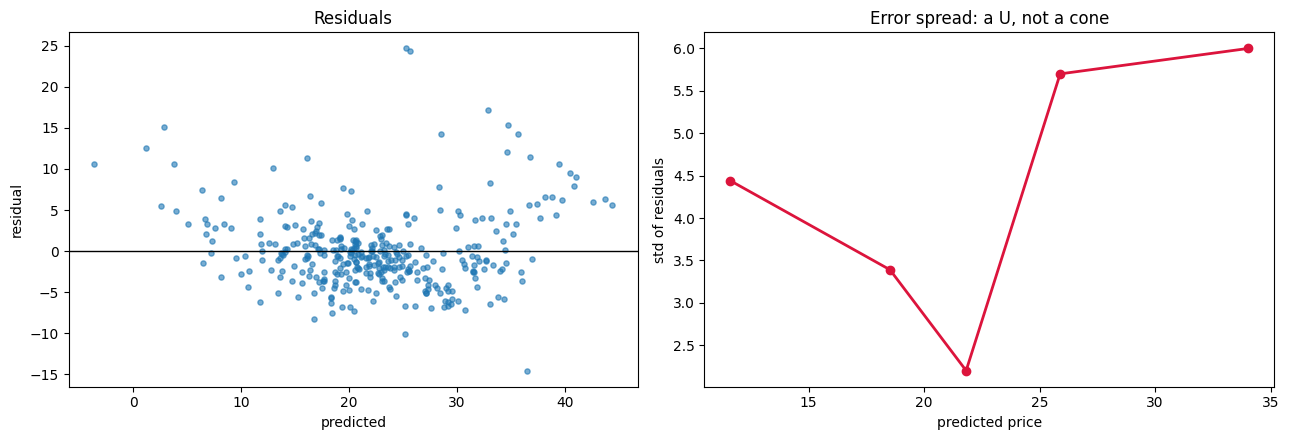

In [ ]:
fitted = boston_predict(estimator, train[FEATURES])
residual = train[TARGET] - fitted
bins = pd.qcut(fitted, 5, labels=False)
spread = pd.DataFrame({"mean_prediction": [fitted[bins == i].mean() for i in range(5)],
                       "residual_std": [residual[bins == i].std() for i in range(5)]}).round(2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(fitted, residual, s=14, alpha=0.6)
axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals")
axes[1].plot(spread.mean_prediction, spread.residual_std, "o-", lw=2, color="crimson")
axes[1].set_xlabel("predicted price"); axes[1].set_ylabel("std of residuals")
axes[1].set_title("Error spread: a U, not a cone")
plt.tight_layout()
print(spread.to_string(index=False))

top = train[fitted > np.percentile(fitted, 80)]
print(f"\ncensored towns overall        : {(train[TARGET] == 50).mean():.1%}")
print(f"censored among top predictions: {(top[TARGET] == 50).mean():.1%}")
print(f"worst single error on validation: {np.abs(val[TARGET] - prediction).max():.2f}, "
      f"on a town priced {val[TARGET].iloc[np.abs(val[TARGET].values - prediction).argmax()]}")

**Conclusion for the report.**

A linear model on these thirteen attributes predicts a town's median house value with an RMSE of
about **4.7 ($4 700)**, against **9.7** for predicting the average — so it removes roughly half the
error. Transforming the two skewed quantities (`log(price)`, `log(LSTAT)`) and adding curvature in
`RM` takes the linear model to **4.18**; a random forest reaches **3.36** and is the best model
tested.

Three limits, each measured rather than asserted:

1. **The target is censored.** 16 towns are recorded at exactly 50.0 because anything above was
   clipped. They are 2.8 % of the training data but 11.3 % of the model's most expensive
   predictions, and they produce the single worst error in the notebook (13.7 on a town priced 50).
   No model can recover a value that was never written down.
2. **The error variance is not constant, and not in the textbook shape.** The residual spread is
   **U-shaped** — widest at the cheap and expensive ends, narrowest in the middle — so a single
   RMSE overstates reliability at both extremes. Note that `log(price)` improves the *score*
   without removing this: the two are different problems.
3. **The split is worth ±0.68 RMSE.** With 506 rows, any comparison made on one split is
   unresolvable. Every number above is a paired mean over 30 splits for that reason.

And one decision that is not statistical: **`B` encodes the proportion of Black residents.**
Dropping it costs +0.07 RMSE — inside the noise band, i.e. nothing. There is no performance
argument for keeping it, so the final model should not.